# Лекция 7. Дифференциально приватное обучение с использованием Opacus

### Подготовка окружения
Грузим все, что можно погрузить, остальное оставляем

In [1]:
# Зависимости и библиотеки; torch намеренно не переустанавливаем.
import copy
import gzip
import importlib.util
import json
import math
import os
import random
import struct
import subprocess
import sys
import time
import urllib.request
from contextlib import nullcontext
from dataclasses import asdict, dataclass
from importlib.metadata import version
from pathlib import Path

# В Colab и Kaggle уже установлена совместимая с GPU версия PyTorch.
# Здесь устанавливаем Opacus и недостающие библиотеки, не заменяя torch.
requirements = {"opacus": "opacus==1.5.4", "numpy": "numpy", "pandas": "pandas",
                "matplotlib": "matplotlib", "sklearn": "scikit-learn>=1.5", "scipy": "scipy"}
missing = [package for module, package in requirements.items()
           if importlib.util.find_spec(module) is None]
if importlib.util.find_spec("opacus") is not None and version("opacus") != "1.5.4":
    missing.append("opacus==1.5.4")
if importlib.util.find_spec("sklearn") is not None and tuple(map(int, version("scikit-learn").split(".")[:2])) < (1, 5):
    missing.append("scikit-learn>=1.5")
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 254.4/254.4 kB 4.0 MB/s eta 0:00:00


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display
from opacus import PrivacyEngine
from opacus.accountants import PRVAccountant, RDPAccountant
from opacus.grad_sample import GradSampleModule
from opacus.optimizers import DPOptimizer
from opacus.utils.batch_memory_manager import BatchMemoryManager
from opacus.validators import ModuleValidator
from scipy.stats import norm
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, roc_auc_score, roc_curve
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import KNeighborsClassifier
import opacus

In [ ]:
# Конфигурация эксперимента. PROFILE меняет объём работы, а DELTA, CLIP_NORM, BATCH_SIZE и PHYSICAL_BATCH — параметры, к которым будем возвращаться. После выбора целевого бюджета количество эпох нельзя менять, не пересчитав шум.
get_ipython().run_line_magic("matplotlib", "inline")
torch.set_num_threads(min(4, os.cpu_count() or 1))
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 12})

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PROFILE = os.environ.get("DP_LAB_PROFILE", "full" if DEVICE.type == "cuda" else "quick")

PROFILES = {
    "full": {"n_train": 8192, "epochs": 50, "small_epochs": 240, "extra": True},
    "quick": {"n_train": 4096, "epochs": 20, "small_epochs": 100, "extra": False},
    "smoke": {"n_train": 512, "epochs": 2, "small_epochs": 2, "extra": True},
}
CFG = PROFILES[PROFILE]

SEED, SPLIT_SEED, DELTA = 23, 2026, 1e-5

LATENT_DIM, CHANNELS = 8, 16
BATCH_SIZE, PHYSICAL_BATCH = 256, 64
CLIP_NORM, BETA = .03, 2.0
START_TIME = time.perf_counter()
RUN_DIR = Path("opacus_lab_runs") / PROFILE
RUN_DIR.mkdir(parents=True, exist_ok=True)

In [5]:
def set_seed(seed):
    """Фиксируем учебный эксперимент; это не настройка production DP."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print(f"PyTorch {torch.__version__}; Opacus {opacus.__version__}; устройство: {DEVICE}; профиль: {PROFILE}")
print(CFG)

PyTorch 2.11.0+cu128; Opacus 1.5.4; устройство: cuda; профиль: full
{'n_train': 8192, 'epochs': 50, 'small_epochs': 240, 'extra': True}


## 1.Подгружаем данные

Мы берём часть MNIST и условно называем её приватной. Отдельные изображения оставляем для публичной диагностики; ещё часть — для кандидатов, которые точно не участвовали в обучении. Такое разделение позволяет честно сделать нужное сравнение.

Метки при обучении VAE не нужны. Они появятся лишь позже, когда захотим понять, что означают латентные коды. Разбиение зафиксируем одним seed, чтобы модели получали одни и те же изображения.

**MNIST не грузится нормально изз torchvision больше, поэтому качаем с официального сайта**

In [ ]:
MNIST_NPZ = None
DATA_DIR = Path("mnist_data")
DATA_DIR.mkdir(exist_ok=True)

def read_idx(filename):
    """Загружаем и читаем официальный gzip/IDX без зависимости от torchvision."""
    path = DATA_DIR / filename
    if not path.exists():
        url = "https://ossci-datasets.s3.amazonaws.com/mnist/" + filename
        for attempt in range(3):
            try:
                with urllib.request.urlopen(url, timeout=30) as response:
                    payload = response.read()
                gzip.decompress(payload)  # Не сохраняем недокачанный файл.
                path.write_bytes(payload)
                break
            except Exception as error:
                if attempt == 2:
                    raise RuntimeError("Включите Internet или задайте MNIST_NPZ.") from error
                time.sleep(1)
    with gzip.open(path, "rb") as source:
        magic = struct.unpack(">I", source.read(4))[0]
        ndim = magic & 255
        assert (magic >> 8) == 8 and ndim in (1, 3)
        shape = struct.unpack(">" + "I" * ndim, source.read(4 * ndim))
        return np.frombuffer(source.read(), dtype=np.uint8).reshape(shape).copy()

In [ ]:
if MNIST_NPZ:
    with np.load(MNIST_NPZ) as archive:
        train_raw, train_labels, test_raw, test_labels = [archive[key] for key in
            ("x_train", "y_train", "x_test", "y_test")]
else:
    train_raw = read_idx("train-images-idx3-ubyte.gz")
    train_labels = read_idx("train-labels-idx1-ubyte.gz")
    test_raw = read_idx("t10k-images-idx3-ubyte.gz")
    test_labels = read_idx("t10k-labels-idx1-ubyte.gz")

In [ ]:
# Разделение данных. Следующая ячейка фиксирует непересекающиеся индексы. Особенно проверьте, что пул неучастников не пересекается с приватным train.
def to_images(array):
    """Все модели получают float32 изображения [N, 1, 28, 28] в диапазоне [0, 1]."""
    return torch.tensor(array, dtype=torch.float32).reshape(-1, 1, 28, 28) / 255.

order = np.random.default_rng(SPLIT_SEED).permutation(len(train_raw))

n_train, n_public, n_nonmember = CFG["n_train"], 4096, 2048
train_ids = order[:n_train]
public_ids = order[n_train:n_train+n_public]
nonmember_ids = order[n_train+n_public:n_train+n_public+n_nonmember]
assert len(np.unique(np.r_[train_ids, public_ids, nonmember_ids])) == n_train+n_public+n_nonmember

X_train = to_images(train_raw[train_ids])
X_public = to_images(train_raw[public_ids])
X_nonmember = to_images(train_raw[nonmember_ids])

y_public = np.asarray(train_labels[public_ids])
X_val, X_test = to_images(test_raw[:512]), to_images(test_raw[1000:2000])
y_test = np.asarray(test_labels[1000:2000])

assert DELTA < 1 / len(X_train)
display(pd.DataFrame({"Выборка": ["Обучение", "Публичная", "Неучастники", "Проверочная", "Тестовая"],
                      "Изображений": list(map(len, [X_train, X_public, X_nonmember, X_val, X_test]))}))

,Выборка,Изображений
0,Обучение,8192
1,Публичная,4096
2,Неучастники,2048
3,Проверочная,512
4,Тестовая,1000


### Уии, рисовалка

In [9]:
# Цвет модели сохраняется между кривыми обучения и графиками атак.
MODEL_COLORS = {
    "Без DP · AdamW": "#2878b5", "Только clipping": "#777777",
    "DP · AdamW · ε=1": "#e58b2a", "DP · AdamW · ε=4": "#29925c",
    "DP · AdamW · ε=8": "#8458a5", "DP · SGD · ε=8": "#c8474d",
    "Малая выборка · без DP": "#2878b5", "Малая выборка · ε=4": "#29925c",
}

# Все подписи к графикам заданы здесь. Функции экспериментов возвращают данные,
# а функции визуализации только показывают их: их можно переиспользовать без обучения.
def finish_figure(fig):
    fig.tight_layout()
    plt.show()

# Для изображений везде одинаковый диапазон [0, 1] и одинаковая палитра.
def image_grid(images, title, columns=8, row_labels=None):
    """Одна сетка для исходных изображений, реконструкций, генерации и соседей."""
    images = torch.as_tensor(images).detach().cpu().reshape(-1, 28, 28)
    rows = math.ceil(len(images) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(columns * .95, rows * 1.05), squeeze=False)
    for axis in axes.flat:
        axis.axis("off")
    for axis, image in zip(axes.flat, images):
        axis.imshow(image, cmap="gray", vmin=0, vmax=1)
    fig.suptitle(title, y=1.02)
    if row_labels:
        # axis.text работает и после axis('off'); метка относится ко всей строке.
        for row, label in enumerate(row_labels):
            axes[row, 0].text(-.15, .5, label, ha="right", va="center",
                              transform=axes[row, 0].transAxes, fontsize=9)
    finish_figure(fig)

In [10]:
def plot_histories(runs):
    """BCE и KL показываем отдельно: изменение β не должно скрывать collapse."""
    fields = [("val_bce", "BCE на пиксель", "Реконструкция на проверочной выборке"),
              ("val_kl", "KL на изображение", "Информация в латентном коде"),
              ("epsilon", "ε", "Расход бюджета")]
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    colors = {run.config.name: MODEL_COLORS.get(run.config.name, plt.get_cmap("tab10")(index))
              for index, run in enumerate(runs)}
    for axis, (field, ylabel, title) in zip(axes, fields):
        for run in runs:
            if field == "epsilon" and not (run.sigma > 0):
                continue
            axis.plot(run.history.epoch, run.history[field], color=colors[run.config.name], label=run.config.name)
        axis.set(xlabel="Эпоха", ylabel=ylabel, title=title)
        axis.grid(alpha=.2)
    axes[0].legend(fontsize=8)
    axes[2].legend(fontsize=8)
    finish_figure(fig)

In [11]:
# PCA/t-SNE нужны для взгляда на коды, а не для доказательства приватности.
def plot_latents(embeddings, labels, method="pca"):
    """Одинаковые изображения, цвета и параметры проекции для каждой модели."""
    columns = 2 if len(embeddings) == 4 else min(3, len(embeddings))
    rows = math.ceil(len(embeddings) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(4.4 * columns, 4 * rows), squeeze=False)
    for axis in axes.flat:
        axis.axis("off")
    for axis, (name, codes) in zip(axes.flat, embeddings.items()):
        axis.axis("on")
        if method == "pca":
            projection = PCA(2).fit_transform(codes)
            xlabel, ylabel = "Первая компонента", "Вторая компонента"
        else:
            # t-SNE не выравнивает координаты разных моделей и может разделять облака
            # сильнее, чем они разделены в исходном пространстве. Ниже считаем и ARI.
            projection = TSNE(n_components=2, init="pca", learning_rate="auto", perplexity=30,
                              max_iter=1000, random_state=SEED, n_jobs=4).fit_transform(codes)
            xlabel, ylabel = "t-SNE 1", "t-SNE 2"
        points = axis.scatter(*projection.T, c=labels, cmap="tab10", vmin=-.5, vmax=9.5,
                              s=9, alpha=.65, linewidths=0)
        axis.set(title=name, xlabel=xlabel, ylabel=ylabel)
    fig.tight_layout(rect=(0, 0, .92, 1))
    color_axis = fig.add_axes([.94, .18, .012, .64])
    fig.colorbar(points, cax=color_axis, ticks=range(10), label="Цифра")
    plt.show()

In [12]:
# Атака визуализирует score и ROC по одним и тем же кандидатам.
def plot_attacks(attack_data, title):
    """ROC и распределение одного и того же score без подбора его знака по test AUC."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for index, (name, (members, nonmembers)) in enumerate(attack_data.items()):
        color = MODEL_COLORS.get(name, plt.get_cmap("tab10")(index))
        labels = np.r_[np.ones(len(members)), np.zeros(len(nonmembers))]
        scores = np.r_[members, nonmembers]
        fpr, tpr, _ = roc_curve(labels, scores)
        auc = roc_auc_score(labels, scores)
        axes[0].plot(fpr, tpr, color=color, label=f"{name}: AUC = {auc:.3f}")
        axes[1].hist(members, bins=25, alpha=.3, color=color, density=True, label=f"{name}, участники")
        axes[1].hist(nonmembers, bins=25, color=color, histtype="step", linewidth=1.5, density=True, label=f"{name}, неучастники")
    axes[0].plot([0, 1], [0, 1], "k--", lw=1)
    axes[0].set(xlabel="Доля ложных срабатываний (FPR)", ylabel="Доля найденных участников (TPR)", title=title)
    axes[1].set(xlabel="Score = −BCE реконструкции", ylabel="Плотность", title="Распределение score")
    for axis in axes:
        axis.legend(fontsize=7)
        axis.grid(alpha=.2)
    finish_figure(fig)

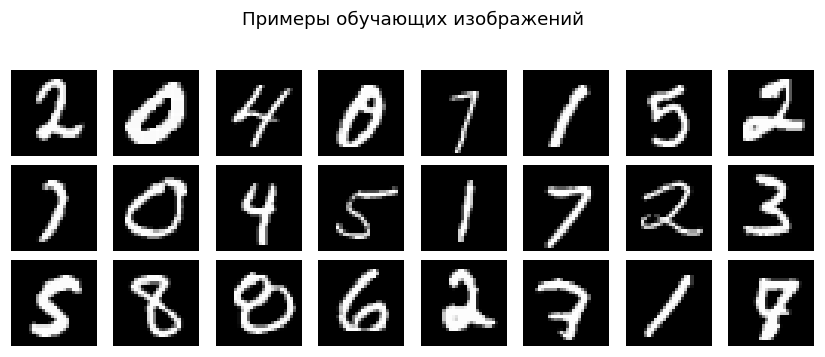

In [13]:
def display_results(frame, decimals=4):
    """Таблицу для расчётов не меняем; форматируем только её отображение."""
    shown = frame.copy().round(decimals)
    if "ε" in shown:
        def format_epsilon(value):
            if pd.isna(value):
                return "—"
            if np.isinf(value):
                return "∞"
            return f"{value:.3f}"
        shown["ε"] = shown["ε"].map(format_epsilon)
    display(shown)


image_grid(X_train[:24], "Примеры обучающих изображений")

## 2. Где обычный SGD перестаёт подходить

**Kindly Reminder**. DP-SGD считает градиент *для каждого объекта отдельно*, ограничивает его длину, складывает обрезанные градиенты и только затем добавляет шум.

Для соседних наборов $D,D'$ алгоритм $M$ должен удовлетворять

$$
\Pr[M(D)\in S]\leq e^{\varepsilon}\Pr[M(D')\in S]+\delta
$$

при любом возможном событии $S$ (в нашем случае это подвыборка). Здесь $\varepsilon$ определяет допустимую разницу вероятностей, а $\delta$ - небольшое послабление к неравенству, которую также иногда называют «вероятностью утечки». В опыте фиксируем $\delta=10^{-5}$ (стандартное значение, зачастую не изменяется).

Если $g_i$ — градиент объекта, а $C$ — граница нормы, то

$$
\bar g_i=g_i\min\!\left(1,\frac C{\|g_i\|_2}\right),\qquad
\widetilde g=\frac{\sum_{i\in B}\bar g_i+\mathcal N(0,\sigma^2 C^2I)}{qN}.
$$

Здесь $q$ — вероятность попадания записи в Poisson batch, $N$ — число записей, $\sigma$ — *noise multiplier*. Мы делим на ожидаемый размер batch $qN$, а не на его случайный фактический размер (чтобы не тратить время каждый раз считать случайные числа). При добавлении или удалении одной записи сумма обрезанных градиентов меняется по норме не более чем на $C$; для замены одной записи граница может достигать $2C$.

### Разбираем clipping на игрушечном примере
Давайте сначала выведем самую простую арифметику без сети. Получившиеся строки — обычные векторы градиентов **до** и **после** ограничения нормы. Затем сверим тот же принцип с `grad_sample`.

In [14]:
# Градиенты здесь заранее заданы, никакого обучения пока нет.
toy_gradients = torch.tensor([[1., 0.], [0., 3.], [6., 8.]])
toy_c = 2.
toy_factors = (toy_c / toy_gradients.norm(dim=1)).clamp(max=1.)
toy_clipped = toy_gradients * toy_factors[:, None]
print("После clipping:\n", toy_clipped)
print("Средний обрезанный градиент:", toy_clipped.mean(0))
assert torch.allclose(toy_clipped[-1], torch.tensor([1.2, 1.6]), atol=1e-6)

set_seed(7)
toy_x, toy_y = torch.randn(8, 3), torch.randn(8, 1)
plain = nn.Linear(3, 1)
wrapped = GradSampleModule(copy.deepcopy(plain), loss_reduction="mean")
(wrapped(toy_x) - toy_y).square().sum(1).mean().backward()
# Первая координата grad_sample нумерует объекты, остальные повторяют форму параметра.
gradients = torch.cat([p.grad_sample.flatten(1) for p in wrapped.parameters()], dim=1)
manual = []
for index in range(len(toy_x)):
    loss = (plain(toy_x[index:index+1]) - toy_y[index:index+1]).square().sum()
    manual.append(torch.cat([g.flatten() for g in torch.autograd.grad(loss, plain.parameters())]))
assert torch.allclose(gradients, torch.stack(manual), atol=2e-6)

После clipping:
 tensor([[1.0000, 0.0000],
        [0.0000, 2.0000],
        [1.2000, 1.6000]])
Средний обрезанный градиент: tensor([0.7333, 1.2000])


/tmp/ipykernel_49/1968194191.py:14: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  (wrapped(toy_x) - toy_y).square().sum(1).mean().backward()


В первой проверке `grad_sample` совпал с независимым `autograd` по одному объекту (ну а как иначе-то). 

In [15]:
# Запасной backend полезен, если позже появятся менее стандартные слои.
# Тот же расчёт через другой backend полезен при добавлении нестандартных слоёв.
functional_model = GradSampleModule(copy.deepcopy(plain), force_functorch=True)
(functional_model(toy_x) - toy_y).square().sum(1).mean().backward()
functional_gradients = torch.cat([p.grad_sample.flatten(1) for p in functional_model.parameters()], dim=1)
assert torch.allclose(gradients, functional_gradients, atol=2e-6)
functional_model.remove_hooks()

bound = .7
factors = (bound / (gradients.norm(dim=1) + 1e-6)).clamp(max=1)
clipped = gradients * factors[:, None]
assert clipped.norm(dim=1).max() <= bound + 1e-6
optimizer = DPOptimizer(torch.optim.SGD(wrapped.parameters(), lr=.1), noise_multiplier=0.,
                        max_grad_norm=bound, expected_batch_size=8)
optimizer.step()
used_gradient = torch.cat([p.grad.flatten() for p in wrapped.parameters()])
assert torch.allclose(used_gradient, clipped.mean(0), atol=2e-6)
wrapped.remove_hooks()

/tmp/ipykernel_49/1163375145.py:4: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  (functional_model(toy_x) - toy_y).square().sum(1).mean().backward()


Визуализируем полученные результаты для игрушечного примера.

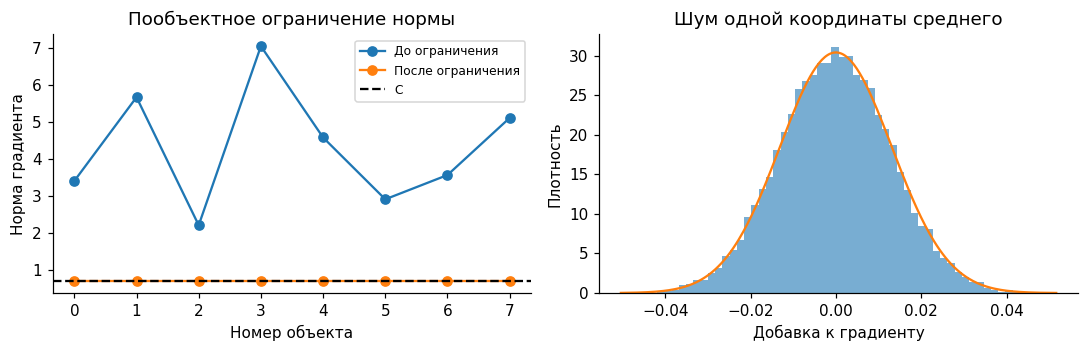

Градиенты, clipping и масштаб шума совпали с ручным расчётом.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))

# Шум симулируется по одной координате среднего градиента: std = σC/b
axes[0].plot(gradients.norm(dim=1), "o-", label="До ограничения")
axes[0].plot(clipped.norm(dim=1), "o-", label="После ограничения")
axes[0].axhline(bound, color="black", ls="--", label="C")
axes[0].set(xlabel="Номер объекта", ylabel="Норма градиента", title="Пообъектное ограничение нормы")
axes[0].legend(fontsize=8)

# Для одной координаты среднего std равен σC/b
sigma_demo, expected_batch = 1.2, 64
noise_std = sigma_demo * bound / expected_batch
noise = np.random.default_rng(1).normal(0, noise_std, 20000)
assert abs(noise.std() / noise_std - 1) < .03

axes[1].hist(noise, bins=60, density=True, alpha=.6)
coordinates = np.linspace(noise.min(), noise.max(), 300)
axes[1].plot(coordinates, norm.pdf(coordinates, scale=noise_std))
axes[1].set(xlabel="Добавка к градиенту", ylabel="Плотность", title="Шум одной координаты среднего")
finish_figure(fig)
print("Градиенты, clipping и масштаб шума совпали с ручным расчётом.")

## 3. Что такое *privacy profile*

В определении DP мы выбираем одно $\varepsilon$ и одно $\delta$. Но можно задать другой вопрос: **если значение $\varepsilon$ уже выбрано, насколько большим должно быть $\delta$, чтобы неравенство выполнялось?** Ответ как функция от $\varepsilon$ и называется *privacy profile* - профилем приватности.

Для двух конкретных распределений выходов $P$ и $Q$ профиль в одном направлении записывается так:

$$
\delta_{P\|Q}(\varepsilon)=\sup_S\left[P(S)-e^{\varepsilon}Q(S)\right].
$$

Супремум означает, что мы ищем **самое неудобное событие** $S$, а не удачно выбранное среднее. Для полной DP-гарантии механизма нужно рассмотреть все соседние датасеты и оба направления сравнения. Ниже мы сделаем гораздо более скромную вещь: проверим профиль **одной пары** распределений.

Пусть на соседних наборах сумма ограниченных градиентов, после нормировки на $C$, равна $0$ и $1$. После Gaussian noise получаем $Q=N(0,\sigma^2)$ и $P=N(1,\sigma^2)$. Их плотности перекрываются. Для этой пары точный профиль равен

$$
\delta(\varepsilon)=\Phi\!\left(\frac1{2\sigma}-\varepsilon\sigma\right)
-e^{\varepsilon}\Phi\!\left(-\frac1{2\sigma}-\varepsilon\sigma\right),
$$

где $\Phi$ — CDF стандартного нормального распределения. При $\varepsilon=0$ профиль совпадает с максимальной разницей вероятностей событий для этих двух распределений (total variation). С ростом $\varepsilon$ допустимое послабление уменьшается. Мы также сравним формулу с Monte Carlo для события $x>\tfrac12+\varepsilon\sigma^2$.

**Граница интерпретации:** точный профиль одного Gaussian mechanism — не профиль всех шагов DP-SGD, там работает сильно более сложная механика, пример чисто ради примера.

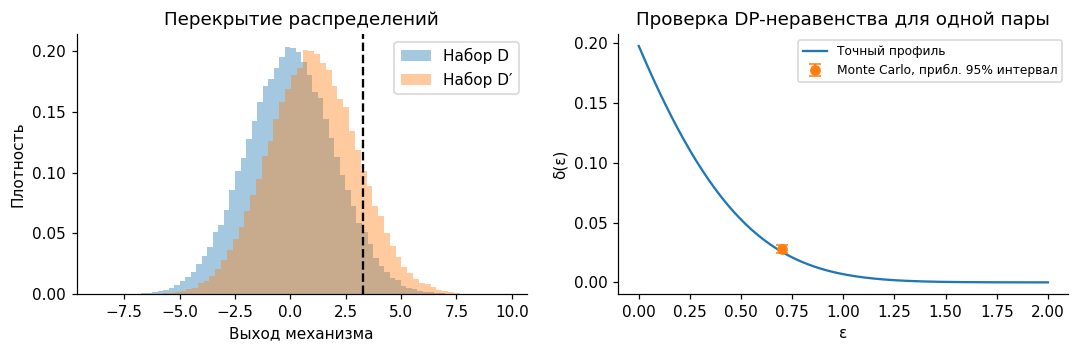

In [ ]:
sigma_gaussian, epsilon_demo = 2., .7
rng = np.random.default_rng(5)

left = rng.normal(0, sigma_gaussian, 100000)
right = rng.normal(1, sigma_gaussian, 100000)

threshold = .5 + epsilon_demo * sigma_gaussian**2
p, q = (right > threshold).mean(), (left > threshold).mean()
estimated_delta = p - np.exp(epsilon_demo) * q
standard_error = np.sqrt(p*(1-p)/len(right) + np.exp(2*epsilon_demo)*q*(1-q)/len(left))
epsilons = np.linspace(0, 2, 200)
exact_delta = (norm.cdf(1/(2*sigma_gaussian)-epsilons*sigma_gaussian)
               - np.exp(epsilons)*norm.cdf(-1/(2*sigma_gaussian)-epsilons*sigma_gaussian))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
axes[0].hist(left, bins=70, density=True, alpha=.4, label="Набор D")
axes[0].hist(right, bins=70, density=True, alpha=.4, label="Набор D′")
axes[0].axvline(threshold, color="black", ls="--")
axes[0].set(xlabel="Выход механизма", ylabel="Плотность", title="Перекрытие распределений")
axes[0].legend()
axes[1].plot(epsilons, exact_delta, label="Точный профиль")
axes[1].errorbar(epsilon_demo, estimated_delta, yerr=1.96*standard_error,
                 fmt="o", capsize=4, label="Monte Carlo, прибл. 95% интервал")
axes[1].set(xlabel="ε", ylabel="δ(ε)", title="Проверка DP-неравенства для одной пары")
axes[1].legend(fontsize=8)
finish_figure(fig)

## 4. Почему бюджет нужно считать по всему обучению

Модель многократно обращается к датасету, и расходы на приватность накапливаются. За этим следит *privacy accountant*. Ему нужны $q$, $\sigma$, число шагов и выбранное $\delta$.

При Poisson sampling каждое изображение независимо выбирается с вероятностью $q$. «Эпоха» поэтому уже не означает, что каждое изображение встретилось ровно один раз: одно могло попасть дважды, другое ни разу. Opacus подбирает $q$ по длине исходного загрузчика, и оно не всегда в точности равно `batch_size/N`.

Один из способов вести учёт — Rényi DP. Для фиксированного порядка $\alpha>1$ вклады шагов суммируются: $\rho_{\mathrm{total}}(\alpha)=\sum_t\rho_t(\alpha)$. Затем из этой оценки получают границу для $(\varepsilon,\delta)$-DP. Вспомним приблизительную запись перехода:

$$
\varepsilon\leq\rho_{\mathrm{total}}(\alpha)+\frac{\log(1/\delta)}{\alpha-1}.
$$

В реальных accountants используются более аккуратные границы: больше шагов обычно тратят больше бюджета, более сильный шум - меньше. Изменение learning rate само по себе в accountant не попадает. И $C$ при фиксированном *noise multiplier* $\sigma$ не меняет учтённое $\varepsilon$, хотя качество модели может измениться сильно.

**Вопросик:** что будет с расходом, если удвоить число шагов? А если оставить число шагов прежним, но сделать batch больше? Во втором вопросе сперва уточните, фиксируем мы **шаги или эпохи**.

In [ ]:
def accounted_epsilon(sigma, sample_rate, steps, delta=DELTA, method="rdp"):
    """Оценка заранее заданной истории без запуска обучения."""
    accountant = RDPAccountant() if method == "rdp" else PRVAccountant()
    accountant.history = [(float(sigma), float(sample_rate), int(steps))]
    return accountant.get_epsilon(delta)

# Учёт без обучения. Мы вручную создаём историю шагов и спрашиваем у accountant бюджет.
original_loader = DataLoader(TensorDataset(X_train), batch_size=BATCH_SIZE, shuffle=True)
sampling_engine = PrivacyEngine(accountant="rdp", secure_mode=False)
sampling_model = nn.Sequential(nn.Flatten(), nn.Linear(784, 1))

sampling_model, sampling_optimizer, poisson_loader = sampling_engine.make_private(
    module=sampling_model, optimizer=torch.optim.SGD(sampling_model.parameters(), lr=.1),
    data_loader=original_loader, noise_multiplier=1., max_grad_norm=CLIP_NORM)

q_main = poisson_loader.sample_rate
batch_sizes = [len(batch) for (batch,) in poisson_loader]

print(type(sampling_model).__name__, type(sampling_optimizer).__name__, type(poisson_loader).__name__)
print(f"q = {q_main:.5f}; ожидаемый batch = {sampling_optimizer.expected_batch_size}")
with torch.no_grad():
    assert sampling_model(X_public[:2]).shape == (2, 1)
sampling_model.remove_hooks()

GradSampleModule DPOptimizer DPDataLoader
q = 0.03125; ожидаемый batch = 256


/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:96: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


**Проверка Poisson loader.** Размеры batches колеблются вокруг ожидаемого. По ним не надо вычислять $q$ задним числом: значение задано самим механизмом.

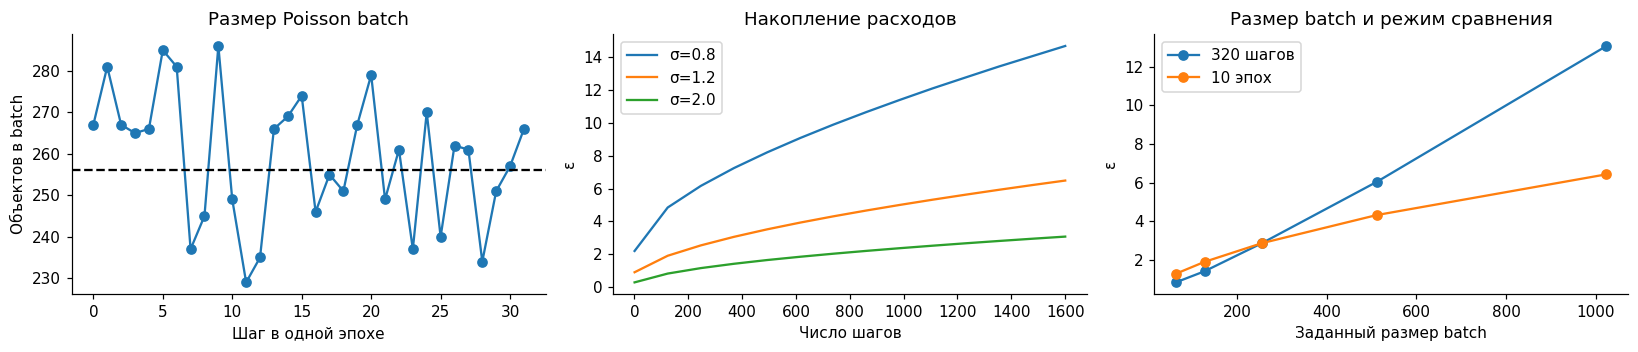

,Accountant,ε
0,rdp,1.759033
1,prv,1.505384


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.3))

axes[0].plot(batch_sizes, "o-")
axes[0].axhline(q_main*len(X_train), color="black", ls="--")
axes[0].set(xlabel="Шаг в одной эпохе", ylabel="Объектов в batch", title="Размер Poisson batch")
steps = np.unique(np.linspace(1, len(original_loader)*CFG["epochs"], 14).astype(int))

for sigma in [.8, 1.2, 2.]:
    axes[1].plot(steps, [accounted_epsilon(sigma, q_main, count) for count in steps], label=f"σ={sigma}")
axes[1].set(xlabel="Число шагов", ylabel="ε", title="Накопление расходов")
axes[1].legend()

for fixed_epochs in [False, True]:
    sizes, values = [64, 128, 256, 512, 1024], []
    for batch_size in sizes:
        batches = math.ceil(len(X_train)/batch_size)
        count = 10*batches if fixed_epochs else 320
        values.append(accounted_epsilon(1.2, 1/batches, count))
    axes[2].plot(sizes, values, "o-", label="10 эпох" if fixed_epochs else "320 шагов")
axes[2].set(xlabel="Заданный размер batch", ylabel="ε", title="Размер batch и режим сравнения")
axes[2].legend()

finish_figure(fig)
display(pd.DataFrame([{ "Accountant": method, "ε": accounted_epsilon(1.2, q_main, 100, method=method)}
                      for method in ["rdp", "prv"]]))
assert accounted_epsilon(2., q_main, 100) < accounted_epsilon(1., q_main, 100)
assert accounted_epsilon(1.2, q_main, 200) > accounted_epsilon(1.2, q_main, 100)

В таблице ниже RDP и PRV считают **одну и ту же последовательность шагов**. Если они дают разные значения $\varepsilon$, это разница в математической оценке (и численной точности), а не в качестве двух моделей. Более точная оценка не отменяет защиту и не улучшает реконструкции: она лишь аккуратнее описывает уже выбранный механизм.

## 5. Тряхнем стариной и вспомним VAE

Для наглядности реконструкции рассмотрим самую простую модель. У VAE для этого есть: *encoder*, переводящий $x$ в распределение скрытого кода и *decoder*, который переводит $z$ обратно в пиксели.

*Encoder* выдаёт $\mu(x)$ и $v(x)=\log\sigma_z^2(x)$. На обучении мы берём $z=\mu+e^{v/2}\odot\xi$, где $\xi\sim N(0,I)$: случайность остаётся, а градиент проходит через параметры *encoder*. *Decoder* возвращает logits для пиксельной BCE, без предварительного `sigmoid`.

$$
\ell_i=\frac{\operatorname{BCE}_{sum}(x_i,\hat x_i)+\beta\operatorname{KL}(q_\phi(z\mid x_i)\|N(0,I))}{784},\qquad
\operatorname{KL}=-\tfrac12\sum_j(1+v_j-\mu_j^2-e^{v_j}).
$$

Первое слагаемое просит восстановить, второе не даёт кодам бесконтрольно разбежаться от нормального prior (хотя, я не дооучил это все и оно бесконттрольно разбежалось...). Мы ставим $\beta=2$. BCE на серых пикселях - просто удобная функция потерь, но буквальная Bernoulli-модель естественнее для бинарных изображений.

Ниже отдельно проверим, что Opacus умеет работать с выбранными слоями.

In [ ]:
# Encoder/decoder определены отдельно; forward связывает их через reparameterization.
class MNISTVAE(nn.Module):
    """Небольшая свёрточная β-VAE. Метки классов при обучении не используются."""
    def __init__(self, latent_dim=LATENT_DIM, channels=CHANNELS):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Conv2d(1, channels, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(channels, 2*channels, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Flatten(),
        )
        hidden_size = 2 * channels * 7 * 7
        self.mean_head = nn.Linear(hidden_size, latent_dim)
        self.logvar_head = nn.Linear(hidden_size, latent_dim)
        # Для ConvTranspose2d Opacus 1.5.4 использует fallback через torch.func;
        # работоспособность этого пути проверяем отдельным backward ниже.
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_size), nn.ReLU(),
            nn.Unflatten(1, (2*channels, 7, 7)),
            nn.ConvTranspose2d(2*channels, channels, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(channels, channels, 3, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(channels, 1, 4, 2, 1),
        )
        nn.init.constant_(self.decoder[-1].bias, -2.)

    def encode(self, images):
        features = self.encoder(images)
        mean = self.mean_head(features)
        logvar = self.logvar_head(features).clamp(-8., 8.)
        return mean, logvar

    def decode(self, latents):
        return self.decoder(latents)  # Возвращаем logits: BCEWithLogits численно устойчивее.

    def forward(self, images, deterministic=False):
        mean, logvar = self.encode(images)
        # Reparameterization сохраняет путь градиента к mean и logvar.
        latents = mean if deterministic else mean + torch.exp(.5*logvar) * torch.randn_like(mean)
        return self.decode(latents), mean, logvar

In [ ]:
# Почему функция потерь возвращает вектор? Для обычного SGD хватило бы одного среднего. 
# Opacus сначала нужен loss каждого изображения: по нему вычисляются отдельные градиенты. 
# В среднем по batch мы сведём значения уже в training loop.
def loss_per_image(output, images, beta=BETA):
    """Вектор loss [batch]; размер batch нигде не смешивается с размером изображения."""
    logits, mean, logvar = output
    bce = F.binary_cross_entropy_with_logits(logits, images, reduction="none").flatten(1).sum(1)
    kl = -.5 * (1 + logvar - mean.square() - logvar.exp()).sum(1)
    # Делим на 784 обе части, сохраняя заданное соотношение BCE и KL.
    return (bce + beta*kl) / 784., bce / 784., kl

### Проверяем совместимость сети до долгого обучения
`ModuleValidator` находит неподдерживаемые слои, а также проверяет, что VAE возвращает градиенты по каждому изображению, а не только общий градиент batch.

In [ ]:
set_seed(SEED)

probe_model = MNISTVAE()

ModuleValidator.validate(probe_model, strict=True)
probe = GradSampleModule(probe_model, loss_reduction="mean")
probe_loss = loss_per_image(probe(X_public[:8]), X_public[:8])[0].mean()
probe_loss.backward()

assert all(p.grad_sample is not None and len(p.grad_sample) == 8 for p in probe.parameters())

public_gradient_norms = torch.sqrt(sum(p.grad_sample.flatten(1).square().sum(1)
                                     for p in probe.parameters())).detach().numpy()
probe.remove_hooks()

print("Параметров модели:", sum(p.numel() for p in MNISTVAE().parameters()))
print("Медиана начальных норм на публичных изображениях:", round(float(np.median(public_gradient_norms)), 4))

# Нормы градиентов вычислены для восьми публичных цифр на случайно инициализированной VAE.
# Пример исправления несовместимого слоя. После fix optimizer создают заново,
# поскольку исправление может вернуть новый модуль с новыми параметрами.
batchnorm_example = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.BatchNorm2d(8))
validation_errors = ModuleValidator.validate(batchnorm_example, strict=False)

assert validation_errors

fixed_example = ModuleValidator.fix(batchnorm_example)
ModuleValidator.validate(fixed_example, strict=True)
print("Пример ModuleValidator.fix:", type(batchnorm_example[1]).__name__, "→", type(fixed_example[1]).__name__)

Параметров модели: 58497
Медиана начальных норм на публичных изображениях: 0.0396
Пример ModuleValidator.fix: BatchNorm2d → GroupNorm


/tmp/ipykernel_49/3576004612.py:7: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  probe_loss.backward()


In [ ]:
# BatchNorm в примере заменён, а исправленный модуль снова проходит валидацию.
# Проверяем не только наличие grad_sample, но и его значения на самой VAE.
# Детерминированный z=mean убирает различие случайных z между batch и циклами по одному объекту.
reference_model = MNISTVAE()
reference_model.load_state_dict(probe_model.state_dict())

gradient_check = GradSampleModule(copy.deepcopy(reference_model))
check_images = X_public[:2]

loss_per_image(gradient_check(check_images, deterministic=True), check_images)[0].mean().backward()
vectorized_gradients = torch.cat([p.grad_sample.flatten(1) for p in gradient_check.parameters()], dim=1)
individual_gradients = []
for image in check_images:
    image = image.unsqueeze(0)
    loss = loss_per_image(reference_model(image, deterministic=True), image)[0].sum()
    gradients = torch.autograd.grad(loss, reference_model.parameters())
    individual_gradients.append(torch.cat([gradient.flatten() for gradient in gradients]))
    
torch.testing.assert_close(vectorized_gradients, torch.stack(individual_gradients), rtol=2e-4, atol=2e-6)
gradient_check.remove_hooks()
print("Per-sample gradients VAE совпали с независимым расчётом по одному изображению.")

Per-sample gradients VAE совпали с независимым расчётом по одному изображению.


/tmp/ipykernel_49/3564393267.py:8: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  loss_per_image(gradient_check(check_images, deterministic=True), check_images)[0].mean().backward()


### Пора выбирать границу $C$

Смотреть на $C$ вслепую не очень полезно (однако, в большинстве случаев ставят $C = 1.0$). Возьмём train sample и посмотрим, какие нормы градиентов получаются у ещё не обученной VAE. На графике будет видно, для какой доли объектов clipping вообще срабатывает.

**Обратите внимание:** меняя $C$ при том же $\sigma$, мы меняем и предел сигнала, и абсолютный масштаб шума. Поэтому accountant может вернуть прежнее $\varepsilon$, даже если оптимизация поведёт себя совсем иначе.

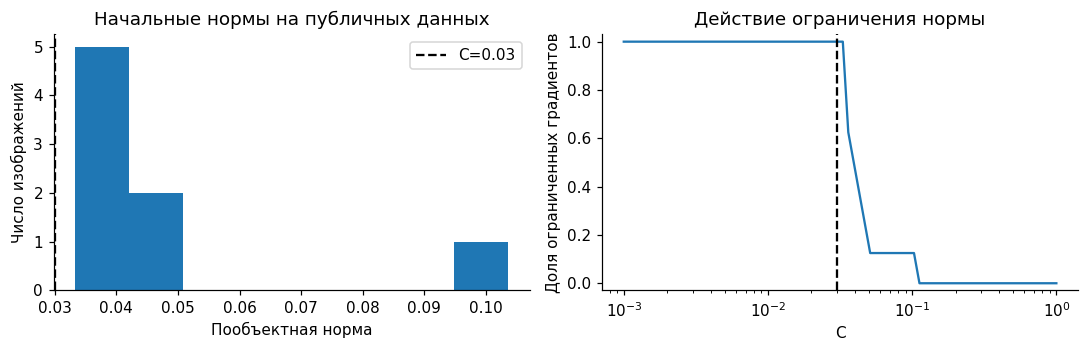

In [ ]:
clip_values = np.logspace(-3, 0, 80)
clipped_fraction = [(public_gradient_norms > bound).mean() for bound in clip_values]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
axes[0].hist(public_gradient_norms, bins=8)
axes[0].axvline(CLIP_NORM, color="black", ls="--", label=f"C={CLIP_NORM}")
axes[0].set(xlabel="Пообъектная норма", ylabel="Число изображений", title="Начальные нормы на публичных данных")
axes[0].legend()
axes[1].semilogx(clip_values, clipped_fraction)
axes[1].axvline(CLIP_NORM, color="black", ls="--")
axes[1].set(xlabel="C", ylabel="Доля ограниченных градиентов", title="Действие ограничения нормы", ylim=(-.03,1.03))
finish_figure(fig)

## 6. Подключаем Opacus к обычному PyTorch

Чтобы не переписывать обучение пять раз, оставим один training loop. В обычном режиме он получит PyTorch optimizer и загрузчик. В DP-режиме `PrivacyEngine` заменит три составляющих:

- Модель получает `grad_sample`: градиенты **каждой записи**, а не только их среднее.
- Optimizer ограничивает эти градиенты, добавляет шум и выполняет один логический шаг.
- DataLoader формирует Poisson batches, на которых основан расчёт бюджета.

`make_private_with_epsilon` подбирает $\sigma$ под запланированные эпохи и целевое $\varepsilon$. Но если затем продолжить обучение, защита не «остановится сама»: accountant продолжит начислять расходы. `make_private` вместо бюджета принимает заданный $\sigma$.

Дальше встретятся *логический* и *физический* batch. Логический определяет **один** зашумлённый шаг и запись в accountant. Физический — лишь часть, которую вычисляем в памяти за раз; `BatchMemoryManager` помогает не превратить каждую такую часть в отдельный DP-шаг. 

**Замечание:** при Poisson sampling возможен даже пустой batch: данных в нём нет, но шумовой шаг и его учёт остаются.

Сначала опишем настройки запуска и функции оценки. Комментарии в цикле отмечают именно те места, где DP отличается от обычного `optimizer.step()`.

In [25]:
@dataclass
class Experiment:
    """Полный план одного обучения. Менять его после калибровки σ нельзя без нового учёта."""
    name: str
    epochs: int = CFG["epochs"]
    optimizer: str = "AdamW"
    lr: float = .002
    epsilon: float | None = None
    sigma: float | None = None
    clip: float = CLIP_NORM
    batch_size: int = BATCH_SIZE
    physical_batch: int = PHYSICAL_BATCH
    beta: float = BETA
    seed: int = SEED


@dataclass
class TrainingRun:
    config: Experiment
    model: nn.Module
    history: pd.DataFrame
    epsilon: float
    sigma: float
    sample_rate: float
    expected_batch_size: int
    steps: int
    seconds: float
    accountant_history: list

In [ ]:
@torch.no_grad()
def evaluate(model, images, beta=BETA):
    """Детерминированная реконструкция через mean, НЕ оценка ELBO."""
    model.eval()
    rows = []
    for batch in images.split(256):
        batch = batch.to(DEVICE)
        output = model(batch, deterministic=True)
        _, bce, kl = loss_per_image(output, batch, beta)
        mse = (output[0].sigmoid() - batch).square().flatten(1).mean(1)
        rows.append(torch.stack([bce, kl, mse], dim=1).cpu())
    return torch.cat(rows).numpy()


def evaluate_run(run, images):
    """Результаты храним на CPU; на GPU переносим только нужную в данный момент модель."""
    run.model.to(DEVICE)
    result = evaluate(run.model, images, run.config.beta)
    run.model.cpu()
    return result

**Метрики.** Валидация использует $z=\mu$, то есть детерминированную реконструкцию.

In [27]:
def save_run(run, experiment_id):
    """Checkpoint для последующей оценки; optimizer/RNG не сохранены, resume здесь не реализован."""
    payload = {"config": asdict(run.config), "model_state": run.model.state_dict(),
               "history": run.history.to_dict(orient="records"), "epsilon": run.epsilon,
               "sigma": run.sigma, "q": run.sample_rate, "expected_batch": run.expected_batch_size,
               "steps": run.steps, "seconds": run.seconds, "accountant_history": run.accountant_history}
    torch.save(payload, RUN_DIR / f"{experiment_id}.pt")

### Где именно включается DP
В следующем коде основной переключатель — наличие `epsilon` или `sigma`. Обратите внимание на последовательность: создать **обычную** модель и optimizer → отдать их `PrivacyEngine` → обучать уже обёрнутые объекты. При `sigma=0` clipping и Poisson sampling сохраняются, а приватной гарантии уже нет.

### Шаг A. Обёртка Opacus

Сначала создаём обычные модель, optimizer и loader. Только после этого `PrivacyEngine` их оборачивает. На выходе получаем те же четыре объекта, но у DP-варианта изменились правила загрузки данных и обновления весов. Обратите внимание: `sigma=0` здесь специально оставлено как контроль clipping-only.

In [ ]:
def configure_training(config, images):
    """Собрать PyTorch-объекты и, при необходимости, превратить их в DP-объекты."""
    model = MNISTVAE().to(DEVICE)
    ModuleValidator.validate(model, strict=True)
    if config.optimizer == "AdamW":
        optimizer = torch.optim.AdamW(model.parameters(), lr=config.lr, weight_decay=1e-4)
    elif config.optimizer == "SGD":
        optimizer = torch.optim.SGD(model.parameters(), lr=config.lr, momentum=.9)
    else:
        raise ValueError(f"Неизвестный optimizer: {config.optimizer}")

    # Исходный loader определяет число логических шагов за эпоху.
    loader = DataLoader(TensorDataset(images), batch_size=config.batch_size, shuffle=True, num_workers=0)
    planned_steps = len(loader) * config.epochs

    engine = None
    if config.epsilon is not None or config.sigma is not None:
        # Создаем приватный движок на основе Renyi DP-механизма
        engine = PrivacyEngine(accountant="rdp", secure_mode=False)
        # Передаем в него необходимые аргументы
        arguments = dict(module=model, optimizer=optimizer, data_loader=loader,
                         max_grad_norm=config.clip, loss_reduction="mean",
                         poisson_sampling=True, grad_sample_mode="hooks")
        # Подбираем параметры приватности
        if config.epsilon is not None:
            # σ подбирается под заранее объявленные epochs и δ.
            model, optimizer, loader = engine.make_private_with_epsilon(
                **arguments, target_epsilon=config.epsilon, target_delta=DELTA, epochs=config.epochs)
        else:
            # sigma=0: Poisson + clipping
            model, optimizer, loader = engine.make_private(
                **arguments, noise_multiplier=config.sigma)
    
    sigma = float(optimizer.noise_multiplier) if engine else 0.
    q = loader.sample_rate if engine else 1 / math.ceil(len(images)/config.batch_size)
    expected_batch = optimizer.expected_batch_size if engine else config.batch_size
    
    return model, optimizer, loader, engine, sigma, q, planned_steps, expected_batch

### Шаг B. Одна эпоха

Внутри цикла обучения спрятана вся механика: отдельные losses, per-sample gradients и логический шаг после нескольких физических порций. Если хочется понять Opacus по-настоящему, то стоит прочитать эту ячейку от `loss.backward()` до `optimizer.step()`. Валидацию поставил отдельно, чтобы она не смешивалась с учётом приватности.

In [ ]:
def epoch_metrics(model, config, engine, sigma, epoch, train_loss):
    """Отдельно считаем utility и расход DP; validation в учебной задаче публичная."""
    values = evaluate(model, X_val, config.beta)
    epsilon = engine.get_epsilon(DELTA) if sigma > 0 else (float("inf") if engine else np.nan)
    return {"epoch": epoch, "train_loss": float(train_loss),
            "val_bce": float(values[:, 0].mean()), "val_kl": float(values[:, 1].mean()),
            "val_mse": float(values[:, 2].mean()), "epsilon": float(epsilon)}


def train_epochs(model, optimizer, loader, engine, sigma, config):
    """Общий цикл: Opacus берёт на себя clipping, noise и учёт logical steps."""
    history = [epoch_metrics(model, config, engine, sigma, 0, np.nan)]
    if engine:
        # Инициализация, так как до первого шага данных ещё не было.
        history[0]["epsilon"] = 0.  

    for epoch in range(1, config.epochs + 1):
        model.train()
        loss_sum, seen = 0., 0
        # Каждый физический batch помещается в память; шум — один раз на логический.
        context = (BatchMemoryManager(data_loader=loader,
                                      max_physical_batch_size=config.physical_batch,
                                      optimizer=optimizer) if engine else nullcontext(loader))
        with context as batches:
            for (batch,) in batches:
                batch = batch.to(DEVICE)
                optimizer.zero_grad()
                # Если собрали батч, то делаем обновление
                if len(batch):
                    losses, _, _ = loss_per_image(model(batch), batch, config.beta)
                    loss = losses.mean()

                    if not torch.isfinite(loss):
                        raise FloatingPointError(f"{config.name}: loss не конечен")
                    
                    loss.backward()  # grad_sample у DP-модели; обычный grad у базовой.
                    loss_sum += float(loss.detach()) * len(batch)
                    seen += len(batch)
                else:
                    # Пустая Poisson выборка: нет вклада данных, но noisy step сохраняем.
                    # Этот обход также нужен fallback sampler для ConvTranspose2d.
                    for parameter in model.parameters():
                        parameter.grad = torch.zeros_like(parameter)
                        parameter.grad_sample = parameter.new_empty((0, *parameter.shape))
                optimizer.step()  # BatchMemoryManager сам выбирает конец logical batch.

        row = epoch_metrics(model, config, engine, sigma, epoch, loss_sum/max(seen, 1))
        history.append(row)
        # Выводим метрики на определённых эпохах
        if epoch == 1 or epoch % max(1, config.epochs//5) == 0 or epoch == config.epochs:
            eps_text = "—" if np.isnan(row["epsilon"]) else (
                "∞" if np.isinf(row["epsilon"]) else f"{row['epsilon']:.3f}")
            print(f"{config.name}: эпоха {epoch}/{config.epochs}, BCE={row['val_bce']:.4f}, "
                  f"KL={row['val_kl']:.2f}, ε={eps_text}", flush=True)
            
    return pd.DataFrame(history)

### Шаг C. Fit/Predict и поехали

`fit_vae` задаёт seed, вызывает обучение, проверяет историю accountant и сохраняет модель.

In [ ]:
def fit_vae(config, images=X_train, experiment_id="run"):
    """Выполнить один план и сохранить итог для повторной оценки без retraining."""
    if config.epsilon is not None and config.sigma is not None:
        raise ValueError("Задайте либо target ε, либо σ, но не оба параметра.")
    
    set_seed(config.seed)  # Одинаковая инициализация для сопоставимых режимов.

    model, optimizer, loader, engine, sigma, q, steps, expected_batch = configure_training(config, images)
    started = time.perf_counter()
    history = train_epochs(model, optimizer, loader, engine, sigma, config)

    accounting_history = copy.deepcopy(engine.accountant.history) if engine else []
    if engine:
        # Физические части не должны умножать число учтённых DP-шагов.
        assert sum(item[2] for item in accounting_history) == steps
        if config.epsilon is not None:
            assert history.iloc[-1]["epsilon"] <= config.epsilon + .03
        
        model = model.to_standard_module()  # Снимает GradSample hooks.

    run = TrainingRun(config, model.cpu().eval(), history, history.iloc[-1]["epsilon"],
                      sigma, q, int(expected_batch), steps,
                      time.perf_counter()-started, accounting_history)
    
    save_run(run, experiment_id)

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    
    return run

## 7. Какие эксперименты смотрим

Теперь у нас есть всё для основного сравнения. 
- AdamW без DP показывает в целом качество обучения модели в стох. режиме;
- Режим **clipping без шума** является контролем оптимизации;
- Остальные модели используют DP-SGD внутри AdamW с заданными бюджетами.

In [31]:
def utility_table(runs):
    rows = []
    for run in runs:
        values = evaluate_run(run, X_test)
        rows.append({"Модель": run.config.name, "ε": run.epsilon, "σ": run.sigma,
                     "C": run.config.clip if run.accountant_history else np.nan,
                     "q": run.sample_rate, "Шагов": run.steps,
                     "BCE": values[:,0].mean(), "MSE": values[:,2].mean(),
                     "Минут": run.seconds / 60})
    return pd.DataFrame(rows)

plans = {
    "nonprivate": Experiment("Без DP · AdamW"),
    "clipping": Experiment("Только clipping", sigma=0.),
    "epsilon1": Experiment("DP · AdamW · ε=1", epsilon=1.),
    "epsilon4": Experiment("DP · AdamW · ε=4", epsilon=4.),
    "epsilon8": Experiment("DP · AdamW · ε=8", epsilon=8.),
    "sgd": Experiment("DP · SGD · ε=8", optimizer="SGD", lr=1., epsilon=8.),
}
# quick сокращает число запусков, а не увеличивает ε уже обученной модели.
run_keys = list(plans) if PROFILE != "quick" else ["nonprivate", "epsilon4", "epsilon8"]
runs = {key: fit_vae(plans[key], experiment_id=key) for key in run_keys}

Без DP · AdamW: эпоха 1/50, BCE=0.2614, KL=3.81, ε=—
Без DP · AdamW: эпоха 10/50, BCE=0.1363, KL=10.72, ε=—
Без DP · AdamW: эпоха 20/50, BCE=0.1272, KL=11.53, ε=—
Без DP · AdamW: эпоха 30/50, BCE=0.1233, KL=12.24, ε=—
Без DP · AdamW: эпоха 40/50, BCE=0.1215, KL=12.37, ε=—
Без DP · AdamW: эпоха 50/50, BCE=0.1198, KL=12.68, ε=—


/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:96: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


Только clipping: эпоха 1/50, BCE=0.2595, KL=3.49, ε=∞
Только clipping: эпоха 10/50, BCE=0.1383, KL=10.39, ε=∞
Только clipping: эпоха 20/50, BCE=0.1281, KL=10.89, ε=∞
Только clipping: эпоха 30/50, BCE=0.1244, KL=12.07, ε=∞
Только clipping: эпоха 40/50, BCE=0.1222, KL=11.84, ε=∞
Только clipping: эпоха 50/50, BCE=0.1216, KL=11.91, ε=∞


/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:96: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


DP · AdamW · ε=1: эпоха 1/50, BCE=0.3633, KL=0.02, ε=0.144


/usr/local/lib/python3.13/dist-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(


... (3 outputs left out)

/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:96: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


DP · AdamW · ε=8: эпоха 1/50, BCE=0.3268, KL=1.11, ε=1.690
DP · AdamW · ε=8: эпоха 10/50, BCE=0.1793, KL=8.48, ε=3.574
DP · AdamW · ε=8: эпоха 20/50, BCE=0.1653, KL=9.11, ε=4.958
DP · AdamW · ε=8: эпоха 30/50, BCE=0.1595, KL=9.41, ε=6.091
DP · AdamW · ε=8: эпоха 40/50, BCE=0.1561, KL=9.57, ε=7.086
DP · AdamW · ε=8: эпоха 50/50, BCE=0.1538, KL=9.51, ε=7.993


/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:96: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


DP · SGD · ε=8: эпоха 1/50, BCE=0.3570, KL=0.07, ε=1.690
DP · SGD · ε=8: эпоха 10/50, BCE=0.1910, KL=7.29, ε=3.574
DP · SGD · ε=8: эпоха 20/50, BCE=0.1699, KL=8.75, ε=4.958
DP · SGD · ε=8: эпоха 30/50, BCE=0.1633, KL=9.10, ε=6.091
DP · SGD · ε=8: эпоха 40/50, BCE=0.1587, KL=9.36, ε=7.086
DP · SGD · ε=8: эпоха 50/50, BCE=0.1556, KL=9.24, ε=7.993


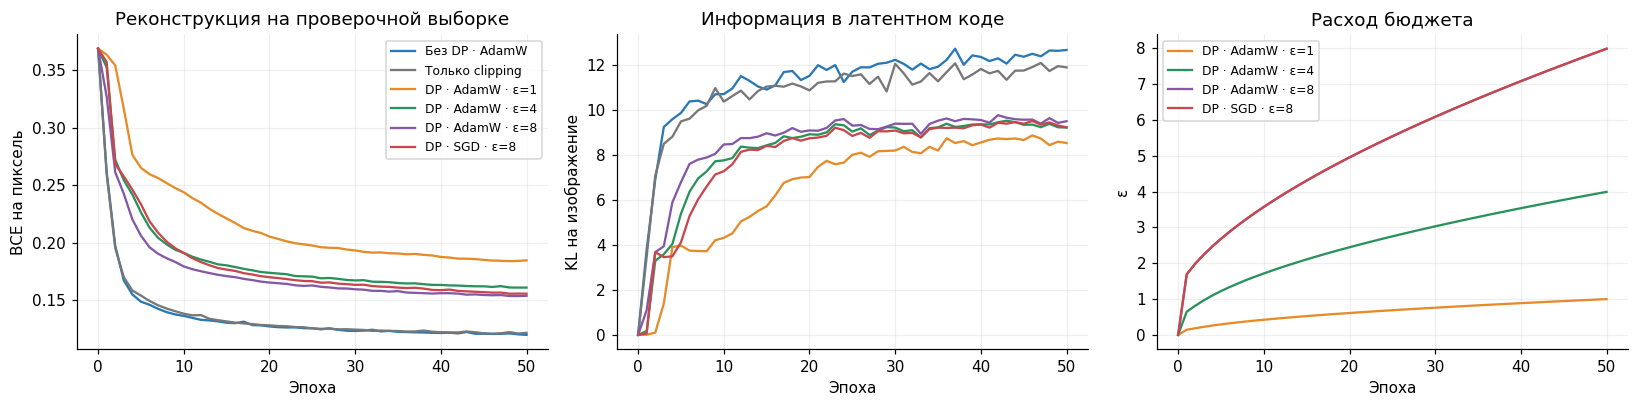

,Модель,ε,σ,C,q,Шагов,BCE,MSE,Минут
0,Без DP · AdamW,—,0.0000,NaN,0.0312,1600,0.1233,0.0207,0.1865
1,Только clipping,∞,0.0000,0.03,0.0312,1600,0.1252,0.0214,1.7189
2,DP · AdamW · ε=1,0.999,5.1562,0.03,0.0312,1600,0.1870,0.0413,1.7456
3,DP · AdamW · ε=4,3.995,1.6455,0.03,0.0312,1600,0.1636,0.0339,1.7570
4,DP · AdamW · ε=8,7.992,1.0669,0.03,0.0312,1600,0.1562,0.0316,1.7819
5,DP · SGD · ε=8,7.992,1.0669,0.03,0.0312,1600,0.1585,0.0323,1.7770


In [32]:
# Теперь обучение закончено. В сохранённом полном прогоне это самая дорогая по времени ячейка. Не меняйте параметры постфактум и не приписывайте старым сохранённым рисункам новый бюджет.
plot_histories(list(runs.values()))
main_results = utility_table(list(runs.values()))
display_results(main_results)
for run in runs.values():
    assert np.isfinite(run.history.val_bce).all()
if PROFILE != "smoke":
    assert runs["epsilon8"].history.val_bce.iloc[-1] < .8 * runs["epsilon8"].history.val_bce.iloc[0]

## 8. Проверки через восстановление и генерацию

При восстановлении *encoder* уже видел изображение; *decoder* получает латент именно этого изображения. В генерации мы не даём модели никакой цифры и берём $z\sim N(0,I)$. Даже хорошо обученный *decoder* может хуже справляться со вторым случаем: области, куда *encoder* помещает настоящие цифры, не обязаны совпадать с типичными точками выбранного prior.

Поэтому ниже будут две серии картинок:
- для восстановления берём одинаковые тестовые цифры;
- для генерации же - одинаковые случайные $z$.

По реконструкциям судим о полезности кодирования; по сэмплам из prior — ещё и о том, насколько удачно устроено латентное распределение. Третья картинка - сдвиг латента между нулем и восьмеркой.

In [33]:
@torch.no_grad()
def latent_codes(run, images):
    run.model.to(DEVICE).eval()
    codes = []
    for batch in images.split(256):
        mean, _ = run.model.encode(batch.to(DEVICE))
        codes.append(mean.cpu())
    run.model.cpu()
    return torch.cat(codes).numpy()

@torch.no_grad()
def reconstruct(run, images):
    run.model.to(DEVICE).eval()
    output, _, _ = run.model(images.to(DEVICE), deterministic=True)
    run.model.cpu()
    return output.sigmoid().cpu()

@torch.no_grad()
def generate(run, count=32, seed=1337):
    # Один и тот же независимый набор z для всех моделей. Никакой фильтрации образцов.
    generator = torch.Generator().manual_seed(seed)
    latents = torch.randn(count, LATENT_DIM, generator=generator).to(DEVICE)
    run.model.to(DEVICE).eval()
    images = run.model.decode(latents).sigmoid().cpu()
    run.model.cpu()
    return images

@torch.no_grad()
def interpolate(run, first, last, steps=8):
    """Линейная интерполяция posterior means двух публичных изображений."""
    run.model.to(DEVICE).eval()
    means, _ = run.model.encode(torch.cat([first, last]).to(DEVICE))
    weights = torch.linspace(0, 1, steps, device=DEVICE)[:, None]
    codes = (1-weights)*means[0] + weights*means[1]
    images = run.model.decode(codes).sigmoid().cpu()
    run.model.cpu()
    return images

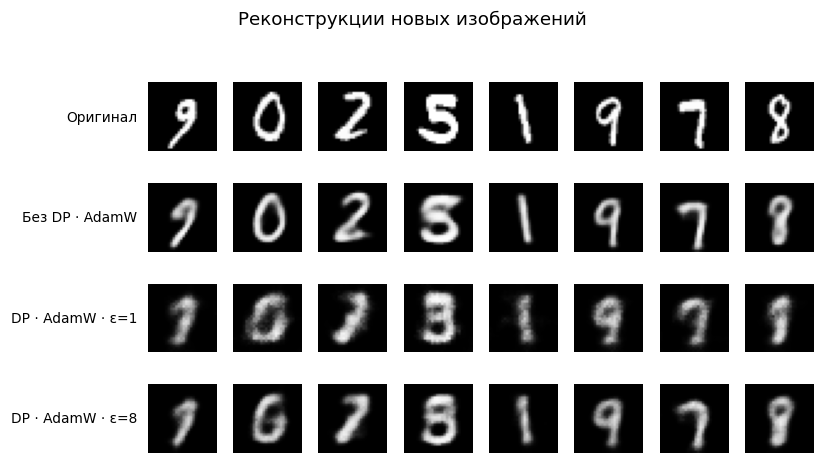

In [34]:
visual_keys = ["nonprivate", "epsilon1", "epsilon8"] if "epsilon1" in runs else ["nonprivate", "epsilon4", "epsilon8"]
comparison_images = [X_test[:8]] + [reconstruct(runs[key], X_test[:8]) for key in visual_keys]
image_grid(torch.cat(comparison_images), "Реконструкции новых изображений", row_labels=["Оригинал"] +
           [runs[key].config.name for key in visual_keys])

Сначала **реконструкции**: слева один и тот же исходный тестовый ряд, ниже ответы моделей.

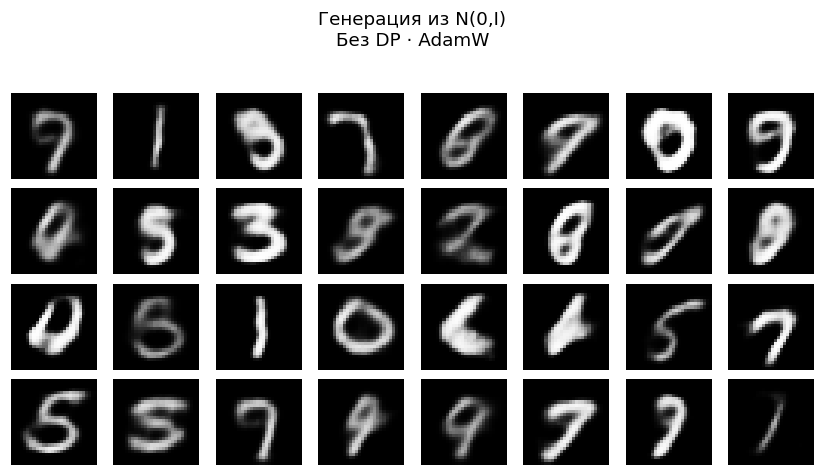

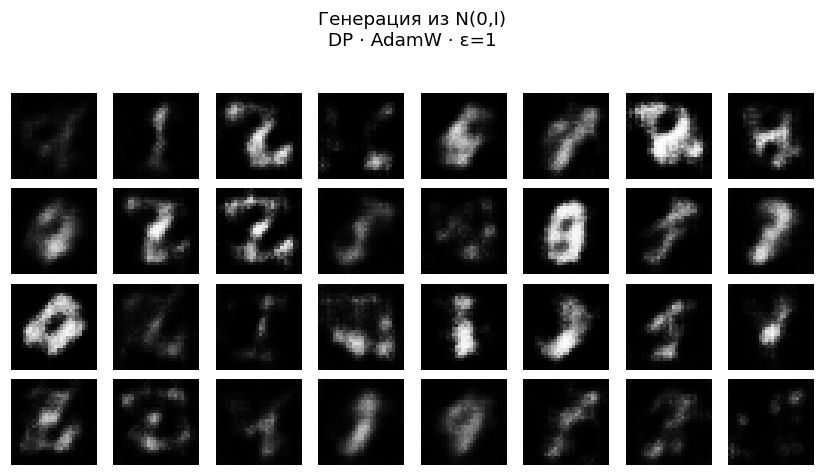

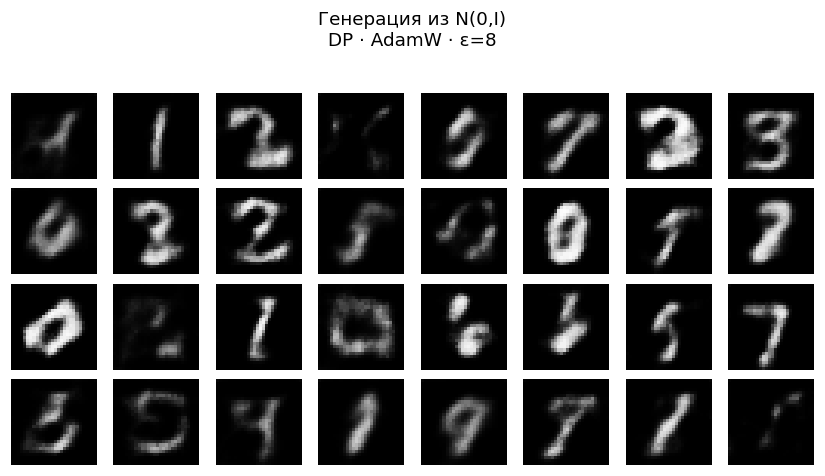

In [35]:
for key in visual_keys:
    image_grid(generate(runs[key]), f"Генерация из N(0,I)\n{runs[key].config.name}")

Затем **генерация**: латенты одинаковы, но декодеры разные.

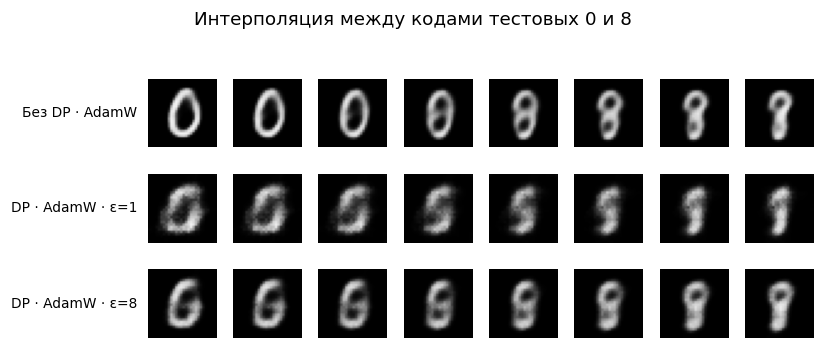

In [36]:
# Берём первые тестовые 0 и 8 по метке, без отбора удачных реконструкций.
zero_index = int(np.flatnonzero(y_test == 0)[0])
eight_index = int(np.flatnonzero(y_test == 8)[0])
interpolations = [interpolate(runs[key], X_test[zero_index:zero_index+1], X_test[eight_index:eight_index+1])
                  for key in visual_keys]
image_grid(torch.cat(interpolations), "Интерполяция между кодами тестовых 0 и 8",
           row_labels=[runs[key].config.name for key in visual_keys])

## 9. Посмотрим на латентное пространство

**Вопросик:** если мы очень хорошо обучили VAE, то как будут расположены относительно друг друга латенты одинаковых чисел?

Мы закодируем одинаковые **тестовые** изображения несколькими моделями. И проверим на двух алгоритмах:
- PCA (покажет направления сильной вариации);
- t-SNE (для кластеризации латентов). 

Чтобы не полагаться на зрение (которое последнее время барахлит), вернёмся к исходным восьмимерным латентам. KMeans разобьёт их на десять групп **без знания меток**; ARI и NMI покажут совпадение разбиения с цифрами. Затем обучим kNN на латентах с метками и проверим его на тесте.

In [37]:
def representation_table(runs, images=X_test, labels=y_test):
    """Оцениваем исходные коды, а не расстояния на t-SNE-картинке."""
    rows, embeddings = [], {}
    for run in runs:
        codes = latent_codes(run, images)
        embeddings[run.config.name] = codes
        # KMeans не получает классы. ARI и NMI сравнивают найденные группы с цифрами.
        clusters = KMeans(n_clusters=10, n_init=10, random_state=SEED).fit_predict(codes)
        public_codes = latent_codes(run, X_public[:2048])
        probe = KNeighborsClassifier(n_neighbors=15).fit(public_codes, y_public[:2048])
        rows.append({"Модель": run.config.name, "ARI": adjusted_rand_score(labels, clusters),
                     "NMI": normalized_mutual_info_score(labels, clusters),
                     "Точность kNN": probe.score(codes, labels),
                     "Активных координат": int((codes.var(0) > .01).sum())})
    return pd.DataFrame(rows), embeddings

,Модель,ARI,NMI,Точность kNN,Активных координат
0,Без обучения,0.1055,0.1905,0.428,0
1,Без DP · AdamW,0.4696,0.5879,0.866,8
2,DP · AdamW · ε=1,0.3034,0.4198,0.761,8
3,DP · AdamW · ε=8,0.3771,0.4896,0.827,8


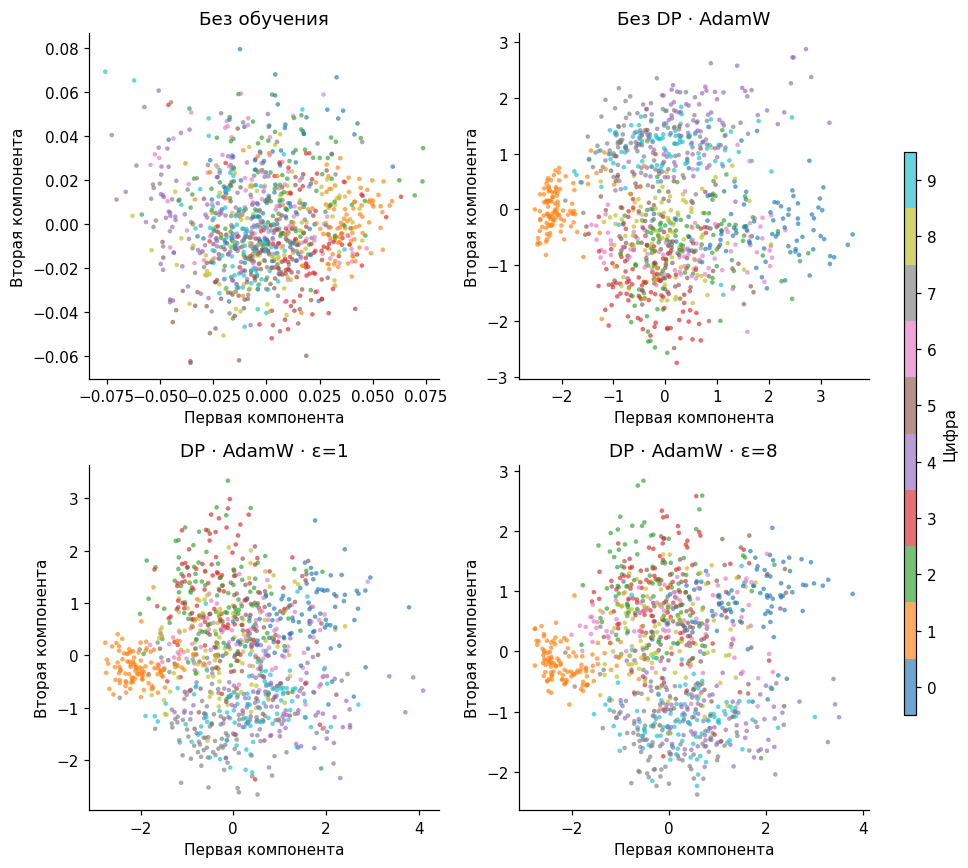

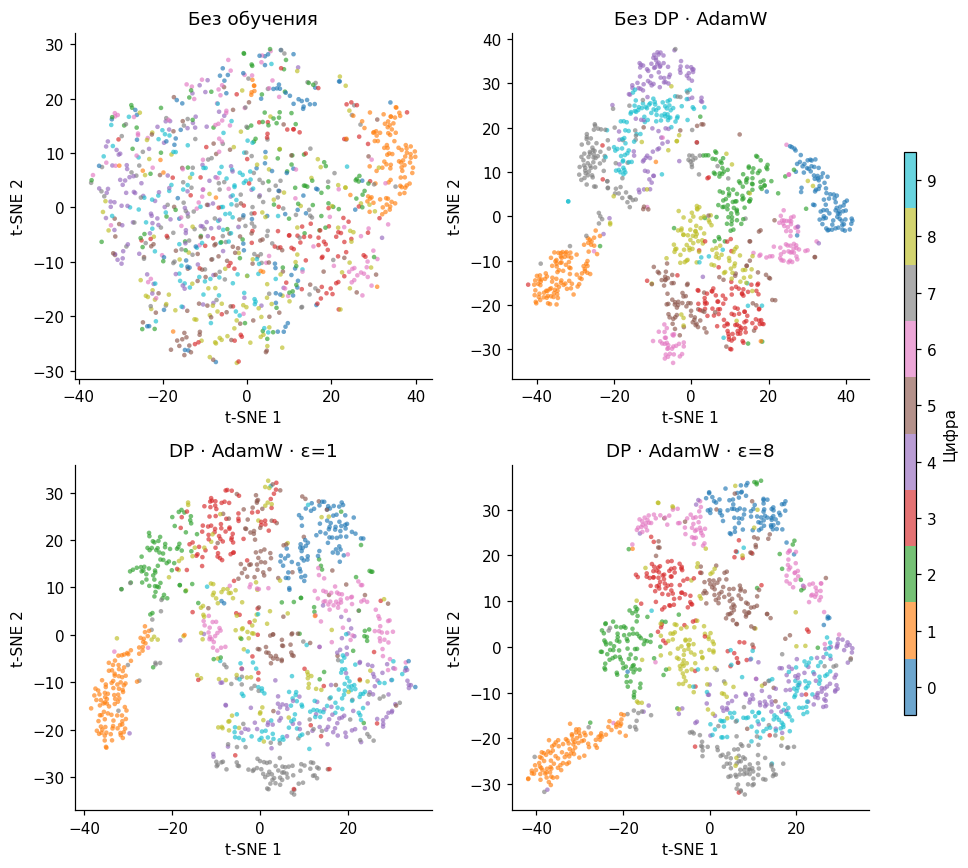

In [ ]:
latent_runs = [runs[key] for key in visual_keys]
if CFG["extra"] and PROFILE != "smoke":
    set_seed(SEED)
    untrained_reference = TrainingRun(
        config=Experiment("Без обучения", epochs=0), model=MNISTVAE().eval(),
        history=pd.DataFrame(), epsilon=0., sigma=0., sample_rate=0.,
        expected_batch_size=0, steps=0, seconds=0., accountant_history=[],
    )
    latent_runs = [untrained_reference] + latent_runs

latent_results, embeddings = representation_table(latent_runs)

display(latent_results.round(4))
plot_latents(embeddings, y_test, method="pca")
plot_latents(embeddings, y_test, method="tsne")

**Замечание:** kNN по латентным кодам даёт **86,6% без DP** и **83,0% при $\varepsilon\approx8$**. Разница есть, но приватная модель явно не превратила все восьмёрки в бесформенное облако. И не должна была. Ограничивать влияние одного изображения — не значит запрещать учить то, что повторяется в тысячах изображений.

## 10. Может ли модель выдать, что видела конкретную цифру?

На большом MNIST модель способна хорошо восстанавливать тестовые изображения, даже почти не выделяя те, на которых училась. Если хотим увидеть *именно запоминание*, условия стоит сделать более жёсткими: оставим **256 изображений**, будем обучать дольше и ослабим KL-регуляризацию до $\beta=0.01$. Это все делается для того, чтобы получить переобучение модели. 

*Атакующий:* есть модель и цифра-кандидат, по которой он реконструирует и спрашивает: «Было ли это изображение в train?» 

Участники порой восстанавливаются точнее, поэтому в качестве score берём **минус BCE**: чем score выше, тем подозрительнее. Здесь атакующий имеет доступ и к *encoder*, и к *decoder*.

Порог для решения будем выбирать по отдельным публичным неучастникам, не подглядывая в ответы на атакуемой выборке. ROC-AUC говорит, насколько хорошо ранжируются участники и неучастники; TPR/FPR описывают конкретный порог. Bootstrap-интервал учитывает конечное число кандидатов при зафиксированных весах.

У малого набора есть ещё одно ограничение: 256 неучастников дают шаг FPR примерно $1/256$. Поэтому не стоит обсуждать по нему фантастически малые ложноположительные частоты. И даже идеальный провал нашей атаки **не был бы доказательством DP**: мы проверили только один способ атаковать модель.

In [39]:
def bootstrap_auc(member_scores, nonmember_scores, repeats=200):
    """Интервал для фиксированной модели: ресемплируются кандидаты, не training seeds."""
    rng = np.random.default_rng(SPLIT_SEED)
    labels = np.r_[np.ones(len(member_scores)), np.zeros(len(nonmember_scores))]
    values = []
    for _ in range(repeats):
        scores = np.r_[rng.choice(member_scores, len(member_scores)),
                       rng.choice(nonmember_scores, len(nonmember_scores))]
        values.append(roc_auc_score(labels, scores))
    return np.quantile(values, [.025, .975])

In [ ]:
# Первая функция только оценивает разброс AUC при повторной выборке кандидатов. 
# Вторая задаёт атаку: score = -BCE, с калибровкой порога и одинаковым числом участников/неучастников.
def membership_experiment(runs, members):
    rows, score_data = [], {}
    count = min(512, len(members), len(X_nonmember))

    for run in runs:
        member_bce = evaluate_run(run, members[:count])[:,0]
        nonmember_bce = evaluate_run(run, X_nonmember[:count])[:,0]
        # Порог задаём на отдельной публичной выборке без использования test members.
        calibration = -evaluate_run(run, X_public[:1000])[:,0]
        threshold = np.quantile(calibration, .99)

        positive, negative = -member_bce, -nonmember_bce
        score_data[run.config.name] = (positive, negative)

        labels = np.r_[np.ones(count), np.zeros(count)]
        auc = roc_auc_score(labels, np.r_[positive, negative])
        low, high = bootstrap_auc(positive, negative, repeats=30 if PROFILE == "smoke" else 200)
        rows.append({"Модель": run.config.name, "BCE train": member_bce.mean(),
                     "BCE nonmember": nonmember_bce.mean(), "AUC": auc, "AUC 2.5%": low,
                     "AUC 97.5%": high, "TPR": (positive >= threshold).mean(),
                     "FPR": (negative >= threshold).mean(), "Кандидатов каждого типа": count})
        
    return pd.DataFrame(rows), score_data

X_small = X_train[:256] if PROFILE != "smoke" else X_train[:128]

small_plans = {
    "small_nonprivate": Experiment("Малая выборка · без DP", epochs=CFG["small_epochs"], beta=.01,
                                    lr=.003, batch_size=64, physical_batch=32),
    "small_private": Experiment("Малая выборка · ε=4", epochs=CFG["small_epochs"], beta=.01,
                                 lr=.003, batch_size=64, physical_batch=32, epsilon=4.),
}
small_runs = {key: fit_vae(plan, images=X_small, experiment_id=key) for key, plan in small_plans.items()}

Малая выборка · без DP: эпоха 1/240, BCE=0.3546, KL=19.62, ε=—
Малая выборка · без DP: эпоха 48/240, BCE=0.1577, KL=109.13, ε=—
Малая выборка · без DP: эпоха 96/240, BCE=0.1786, KL=119.89, ε=—
Малая выборка · без DP: эпоха 144/240, BCE=0.1960, KL=122.11, ε=—
Малая выборка · без DP: эпоха 192/240, BCE=0.2204, KL=117.54, ε=—
Малая выборка · без DP: эпоха 240/240, BCE=0.2303, KL=104.12, ε=—


/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:96: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


Малая выборка · ε=4: эпоха 1/240, BCE=0.3684, KL=0.01, ε=0.216
Малая выборка · ε=4: эпоха 48/240, BCE=0.3599, KL=0.36, ε=1.640
Малая выборка · ε=4: эпоха 96/240, BCE=0.2851, KL=21.22, ε=2.396
Малая выборка · ε=4: эпоха 144/240, BCE=0.2695, KL=36.24, ε=3.000
Малая выборка · ε=4: эпоха 192/240, BCE=0.2580, KL=31.86, ε=3.524
Малая выборка · ε=4: эпоха 240/240, BCE=0.2544, KL=29.32, ε=3.996


,Модель,BCE train,BCE nonmember,AUC,AUC 2.5%,AUC 97.5%,TPR,FPR,Кандидатов каждого типа
0,Без DP · AdamW,0.1174,0.1219,0.5225,0.4903,0.5638,0.0176,0.0117,512
1,DP · AdamW · ε=8,0.1539,0.1562,0.5047,0.4711,0.5403,0.0176,0.0156,512


,Модель,BCE train,BCE nonmember,AUC,AUC 2.5%,AUC 97.5%,TPR,FPR,Кандидатов каждого типа
0,Малая выборка · без DP,0.0767,0.2442,0.9192,0.8933,0.9433,0.0703,0.0078,256
1,Малая выборка · ε=4,0.2536,0.2679,0.5504,0.4944,0.5917,0.0391,0.0117,256


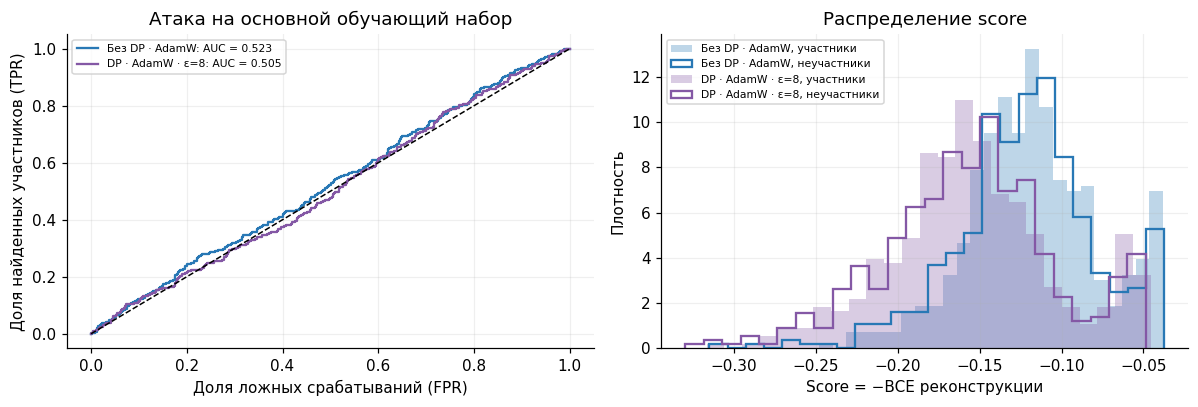

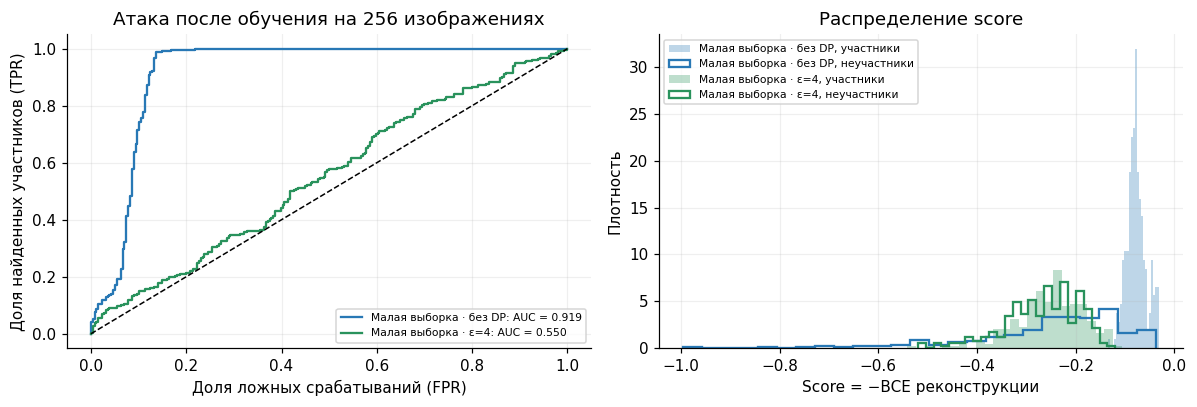

In [ ]:
main_attack_results, main_scores = membership_experiment([runs["nonprivate"], runs["epsilon8"]], X_train)
small_attack_results, small_scores = membership_experiment(list(small_runs.values()), X_small)

display(main_attack_results.round(4)); display(small_attack_results.round(4))
plot_attacks(main_scores, "Атака на основной обучающий набор")
plot_attacks(small_scores, "Атака после обучения на 256 изображениях")

Посмотрим, действительно ли малая неприватная модель точнее восстанавливает свои обучающие изображения.

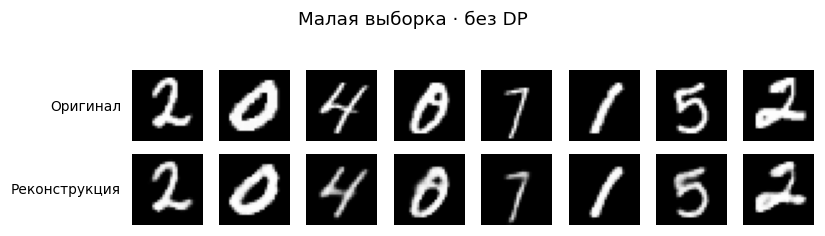

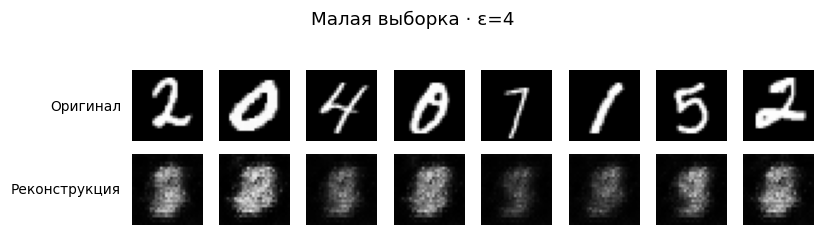

In [42]:
for run in small_runs.values():
    image_grid(torch.cat([X_small[:8], reconstruct(run, X_small[:8])]), run.config.name,
               row_labels=["Оригинал", "Реконструкция"])

Здесь наконец видна разница. В сохранённом полном запуске на большой выборке атака на неприватную VAE дала **AUC 0,521**, почти случайное ранжирование. На 256 изображениях неприватная модель стала заметно отличать участников: **AUC 0,927**. У DP-модели на той же малой выборке получилось **0,552**. Хорошо смотреть не только на три числа, но и на перекрытие распределений score.

### А что если просто найти похожую цифру?

Посмотрим на ближайшего соседа сгенерированного изображения среди train и среди столь же большого пула неучастников. У рукописных единиц не так много принципиально разных способов выглядеть, причем обратное тоже верно - отсутствие почти точной копии не доказывает отсутствие утечки.

Для полноты нарисуем формальную границу для бинарных тестов, вытекающую из $(\varepsilon,\delta)$-DP:

$$
\operatorname{TPR}\le e^\varepsilon\operatorname{FPR}+\delta,
\qquad
\operatorname{TPR}\le1-e^{-\varepsilon}(1-\operatorname{FPR}-\delta).
$$

Это границы для фиксированных соседних датасетов и распределений запусков механизма. Наш ROC, наоборот, построен на множестве кандидатов при одной обученной модели.

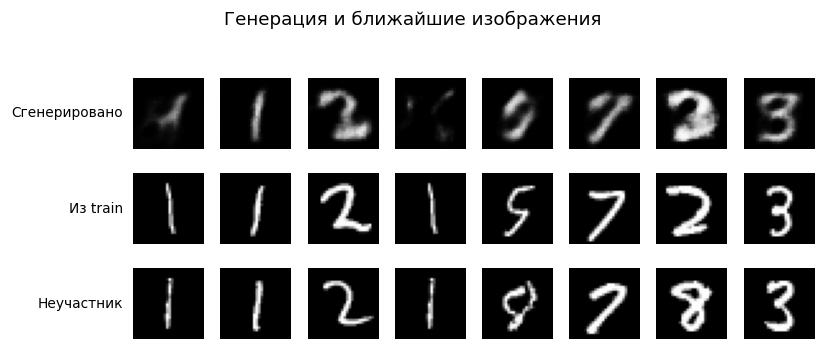

In [43]:
# Сравниваем одинаковые размеры пулов, иначе nearest-neighbor distance смещается.
samples = generate(runs["epsilon8"], count=8)
pool_size = min(512, len(X_train))
train_pool, other_pool = X_train[:pool_size], X_nonmember[:pool_size]
train_nearest = train_pool[torch.cdist(samples.flatten(1), train_pool.flatten(1)).argmin(1)]
other_nearest = other_pool[torch.cdist(samples.flatten(1), other_pool.flatten(1)).argmin(1)]
image_grid(torch.cat([samples, train_nearest, other_nearest]), "Генерация и ближайшие изображения",
           row_labels=["Сгенерировано", "Из train", "Неучастник"])

Подходящие пиксельные соседи встречаются и среди неучастников. Визуальная похожесть сама по себе слишком слабое свидетельство запоминания.

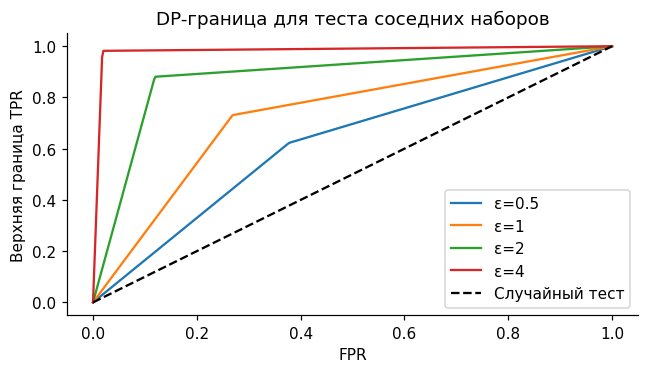

In [44]:
fpr_grid = np.linspace(0, 1, 400)
fig, axis = plt.subplots(figsize=(6, 3.5))
for epsilon in [.5, 1., 2., 4.]:
    upper = np.minimum(1, np.minimum(np.exp(epsilon)*fpr_grid+DELTA,
                       1-np.exp(-epsilon)*(1-fpr_grid-DELTA)))
    axis.plot(fpr_grid, upper, label=f"ε={epsilon:g}")
axis.plot(fpr_grid, fpr_grid, "k--", label="Случайный тест")
axis.set(xlabel="FPR", ylabel="Верхняя граница TPR", title="DP-граница для теста соседних наборов")
axis.legend(); finish_figure(fig)

## Дополнение. Как не потратить всю память на DP-SGD

На реальных сетях `grad_sample` часто становится главным потребителем памяти. Тогда один логический batch считают по частям. Прикол, который придумали: optimizer получает вызов `step()` после каждой *физической* порции, но `BatchMemoryManager` делает настоящее обновление и добавляет шум только на границе *логического* batch.

Ниже есть короткий технический тест. На детерминированной линейной модели сравнивается одно обновление целиком и в четырёх порциях, фиксируя генератор шума. Затем проверяеем пустой Poisson batch и восстановление расходов из сохранённой истории accountant.

In [ ]:
def one_logical_update(physical_batch):
    set_seed(100)

    x = torch.arange(48, dtype=torch.float32).reshape(16, 3) / 48
    y = torch.sin(x[:, :1])

    model = nn.Linear(3, 1)

    loader = DataLoader(TensorDataset(x, y), batch_size=16,
                        generator=torch.Generator().manual_seed(44))
    
    engine = PrivacyEngine(accountant="rdp", secure_mode=False)

    model, optimizer, loader = engine.make_private(
        module=model, optimizer=torch.optim.SGD(model.parameters(), lr=.1), data_loader=loader,
        noise_multiplier=.8, max_grad_norm=.7, noise_generator=torch.Generator().manual_seed(555))
    
    with BatchMemoryManager(data_loader=loader, max_physical_batch_size=physical_batch,
                            optimizer=optimizer) as batches:
        for x_batch, y_batch in batches:
            optimizer.zero_grad()
            (model(x_batch)-y_batch).square().mean().backward()
            optimizer.step()
            
    weights = torch.cat([p.detach().flatten() for p in model.parameters()])
    steps = sum(item[2] for item in engine.accountant.history)
    model.remove_hooks()
    return weights, steps

Проверяем не время, а *эквивалентность одного зашумлённого обновления* при двух физических размерах batch.

In [ ]:
whole, whole_steps = one_logical_update(16)
split, split_steps = one_logical_update(4)
assert whole_steps == split_steps == 1
assert torch.allclose(whole, split, atol=2e-6)

# Проверка пустого batch вынесена отдельно: нельзя просто пропустить шумовой шаг потому, что загрузчик вернул ноль изображений.
empty_model = MNISTVAE()
empty_engine = PrivacyEngine(accountant="rdp", secure_mode=False)

empty_model, empty_optimizer, _ = empty_engine.make_private(
    module=empty_model, optimizer=torch.optim.SGD(empty_model.parameters(), lr=.1),
    data_loader=DataLoader(TensorDataset(X_public[:16]), batch_size=8),
    noise_multiplier=1., max_grad_norm=CLIP_NORM)

empty_optimizer.zero_grad()

for parameter in empty_model.parameters():
    parameter.grad = torch.zeros_like(parameter)
    parameter.grad_sample = parameter.new_empty((0, *parameter.shape))
    
empty_optimizer.step()
assert sum(item[2] for item in empty_engine.accountant.history) == 1
assert all(torch.isfinite(parameter).all() for parameter in empty_model.parameters())
empty_model.remove_hooks()

/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:96: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
/tmp/ipykernel_49/1698710841.py:16: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  (model(x_batch)-y_batch).square().mean().backward()


In [ ]:
# После обучения accountant можно восстановить по истории шагов.
restored_accountant = RDPAccountant()
restored_accountant.history = copy.deepcopy(runs["epsilon8"].accountant_history)

assert abs(restored_accountant.get_epsilon(DELTA)-runs["epsilon8"].epsilon) < 1e-8
print("Разбиение batch, пустой noisy step и восстановление истории accountant проверены.")

Разбиение batch, пустой noisy step и восстановление истории accountant проверены.


In [48]:
private_runs = [run for run in runs.values() if run.sigma > 0]
print("Основные DP-модели, basic composition:")
print(f"ε_total ≤ {sum(run.epsilon for run in private_runs):.3f}; δ_total = {len(private_runs)*DELTA:g}")
print("Это сумма только основных DP-запусков; отдельно обученная малая DP-модель сюда не включена.")
print("Если выпускать также неприватные модели на секретных данных, общей DP-гарантии не будет.")
validation_summary = {
    "profile": PROFILE, "device": str(DEVICE), "torch": str(torch.__version__), "opacus": opacus.__version__,
    "elapsed_minutes": round((time.perf_counter()-START_TIME)/60, 2),
}
print(json.dumps(validation_summary, ensure_ascii=False, indent=2))

Основные DP-модели, basic composition:
ε_total ≤ 20.979; δ_total = 4e-05
Это сумма только основных DP-запусков; отдельно обученная малая DP-модель сюда не включена.
Если выпускать также неприватные модели на секретных данных, общей DP-гарантии не будет.
{
  "profile": "full",
  "device": "cuda",
  "torch": "2.11.0+cu128",
  "opacus": "1.5.4",
  "elapsed_minutes": 11.29
}


## Что почитать

- [Abadi et al., *Deep Learning with Differential Privacy*](https://arxiv.org/abs/1607.00133) — базовый DP-SGD и пообъектное ограничение нормы.
- [Yousefpour et al., *Opacus*](https://arxiv.org/abs/2109.12298) — устройство библиотеки и per-sample gradients.
- [Opacus: PrivacyEngine](https://opacus.ai/api/privacy_engine.html), [BatchMemoryManager](https://opacus.ai/api/batch_memory_manager.html), [GradSampleModule](https://opacus.ai/api/grad_sample_module.html), [ModuleValidator](https://opacus.ai/tutorials/guide_to_module_validator) — детали API.
- [Balle & Wang, *Analytical Gaussian Mechanism*](https://arxiv.org/abs/1805.06530) — точная граница для Gaussian mechanism и связь с privacy profile.
- [Kingma & Welling, *Auto-Encoding Variational Bayes*](https://arxiv.org/abs/1312.6114) — VAE, ELBO и reparameterization.